In [12]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# Load the Tips dataset
df = sns.load_dataset('tips')

# View the first few rows of either to verify
print(df.head())

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


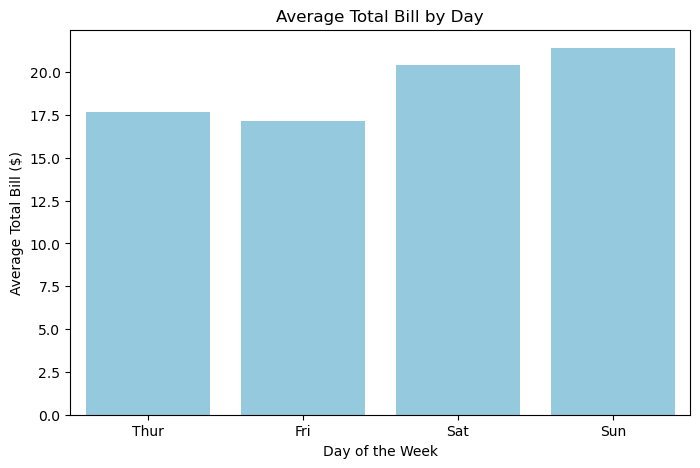

In [13]:
# Task 1 

plt.figure(figsize=(8, 5))
sns.barplot(data= df, x='day', y='total_bill', errorbar=None, color='skyblue')

plt.title('Average Total Bill by Day')
plt.xlabel('Day of the Week')
plt.ylabel('Average Total Bill ($)')
plt.show()

C:\Users\armug\AppData\Local\Temp\ipykernel_5884\1158981563.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data= df, x='day', palette='Set2')


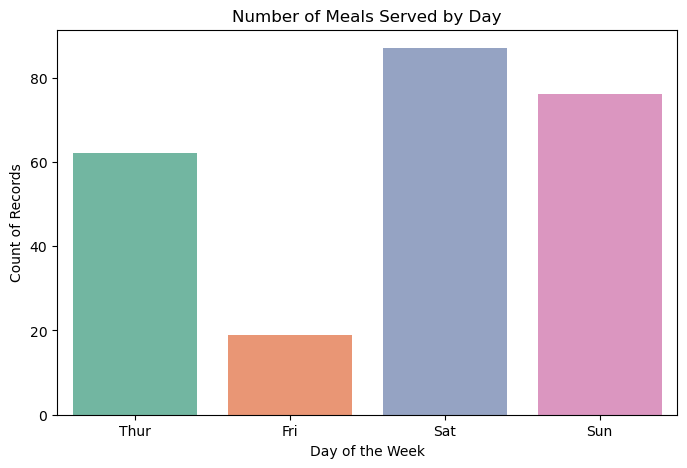

In [14]:
# Task 2 

plt.figure(figsize=(8, 5))
sns.countplot(data= df, x='day', palette='Set2')

plt.title('Number of Meals Served by Day')
plt.xlabel('Day of the Week')
plt.ylabel('Count of Records')
plt.show()

### The most common category for the days of the week is Saturday ###

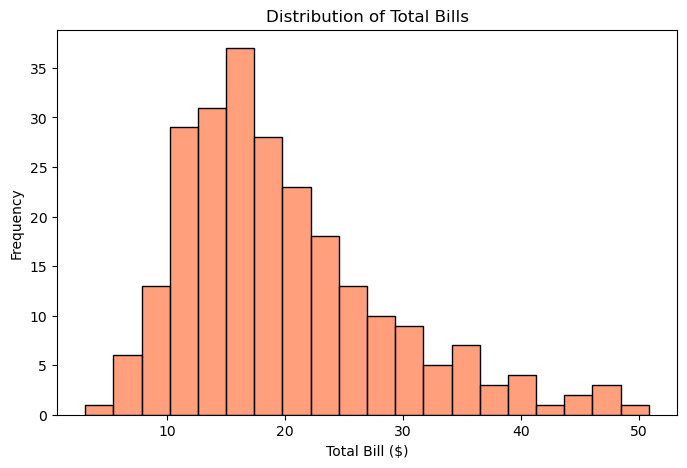

In [15]:
# Task 3 

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='total_bill', bins=20, color='coral')

plt.title('Distribution of Total Bills')
plt.xlabel('Total Bill ($)')
plt.ylabel('Frequency')
plt.show()

### The distribution of the total_bill column is skewed right, which means that most of the bills fall on the lower end (10 to 20). ###

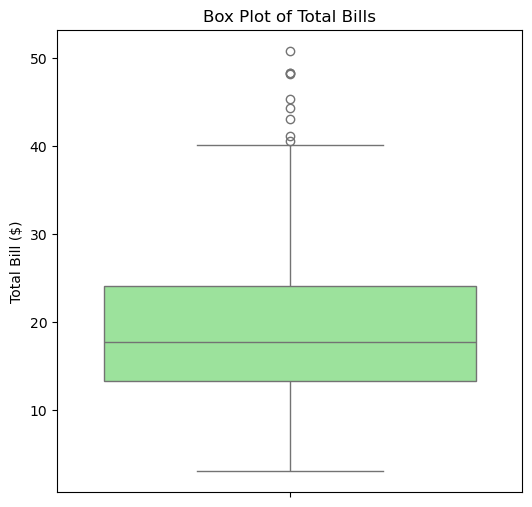

In [16]:
# Task 4 

plt.figure(figsize=(6, 6))
sns.boxplot(data=df, y='total_bill', color='lightgreen')

plt.title('Box Plot of Total Bills')
plt.ylabel('Total Bill ($)')
plt.show()

# there are 9 outliers

In [18]:
# Task 5

Q1 = df['total_bill'].quantile(0.25)
Q3 = df['total_bill'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = df[(df['total_bill'] < lower) | (df['total_bill'] > upper)]
print(len(outliers))

9


In [21]:
# Task 6

from scipy import stats
df['zscore'] = stats.zscore(df['total_bill'])
outliers_z = df[df['zscore'].abs() > 3]
print(len(outliers_z))

4


### Comparison of Outliers Through Z score and IQR ###
No, the IQR and Z-score methods do not flag the same number of outliers i.e IQR finds 9, while Z-score finds 4).

In Task 4, the total_bill distribution is heavily right-skewed and The Z-score method performs poorly on skewed data because it assumes symmetry around the mean.

The few massive extremes inflate the standard deviation, which artificially widens the normal range and hides other outliers. While, the IQR method does not assume a specific distribution shape and is robust to extreme values because it relies on quartiles.

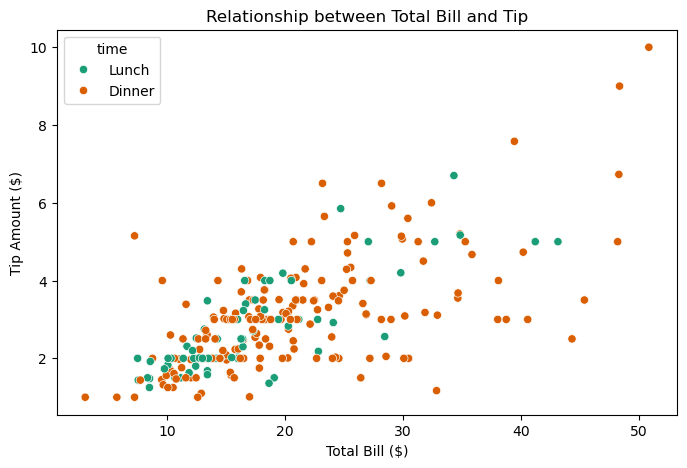

In [22]:
# Task 7 

plt.figure(figsize=(8, 5))
# Plotting total_bill vs tip, colored by meal time
sns.scatterplot(data=tips, x='total_bill', y='tip', hue='time', palette='Dark2')

plt.title('Relationship between Total Bill and Tip')
plt.xlabel('Total Bill ($)')
plt.ylabel('Tip Amount ($)')
plt.show()

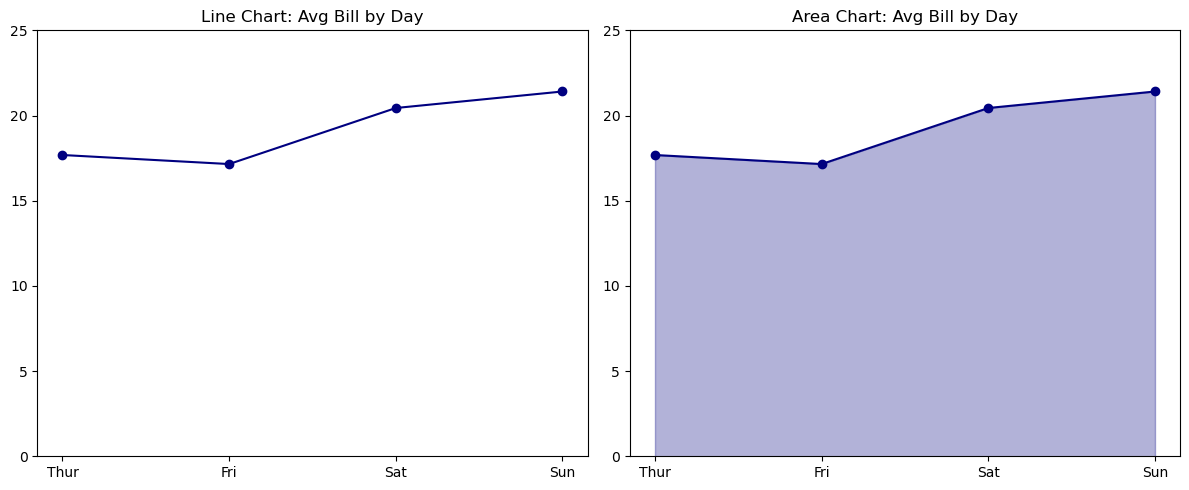

In [23]:
# Task 8

daily_avg = tips.groupby('day', observed=True)['total_bill'].mean().reset_index()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(daily_avg['day'], daily_avg['total_bill'], marker='o', color='navy')
plt.title('Line Chart: Avg Bill by Day')
plt.ylim(0, 25)

plt.subplot(1, 2, 2)
plt.fill_between(daily_avg['day'], daily_avg['total_bill'], color='navy', alpha=0.3)
plt.plot(daily_avg['day'], daily_avg['total_bill'], marker='o', color='navy')
plt.title('Area Chart: Avg Bill by Day')
plt.ylim(0, 25)

plt.tight_layout()
plt.show()


# It draws the viewer's attention to the overall magnitude and accumulated volume of the data, rather than just the direction of the trend.

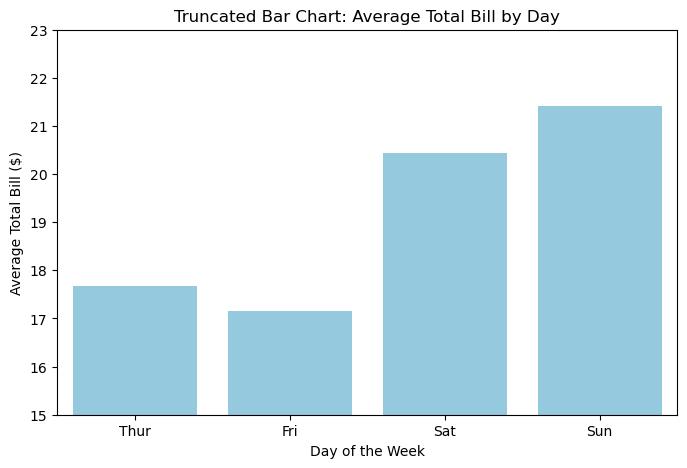

In [24]:
# Task 9

plt.figure(figsize=(8, 5))
sns.barplot(data=tips, x='day', y='total_bill', errorbar=None, color='skyblue')

plt.ylim(15, 23)

plt.title('Truncated Bar Chart: Average Total Bill by Day')
plt.xlabel('Day of the Week')
plt.ylabel('Average Total Bill ($)')
plt.show()

In [25]:
df.to_csv('tips_dataset.csv', index=False)

### Comparison of task 2 chart and task 9 ###

The truncated chart makes it look like the differences between the data is alot , in this graph it looks like the difference between the data of the days is alot whereas in the graph in task 2 it didn't look like there was much of a difference between them. This graph gives a zoomed in view of the data which highlights the difference between the data.  